In [60]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold
from matplotlib import cm
from matplotlib.colors import Normalize

# Specify the path to the pickle file
pickle_file_path = 'Data_MN_Model/Data_Mario/E3_MB01_Day10High_15.pkl'  # Replace with your pickle file path

# Load the pickle data
with open(pickle_file_path, 'rb') as f:
    data = pickle.load(f)

# Print the loaded data
print(data.keys())  # This will show you the available keys in the dictionary

dict_keys(['MU', 'EMG', 'Force', 'Idx_MU_Pair', 'ToI', 'Gain', 't', 'idx', 'FOffsetMVC', 'fsamp'])


In [58]:
idx= data['idx'][0][0]
idx= idx-1
data_MU= data['MU']
data_MU= data_MU[idx]

In [41]:
idx

array([ 3, 12,  0, 11, 15,  5, 14,  9,  6,  8,  7,  1, 10,  2,  4, 13],
      dtype=uint8)

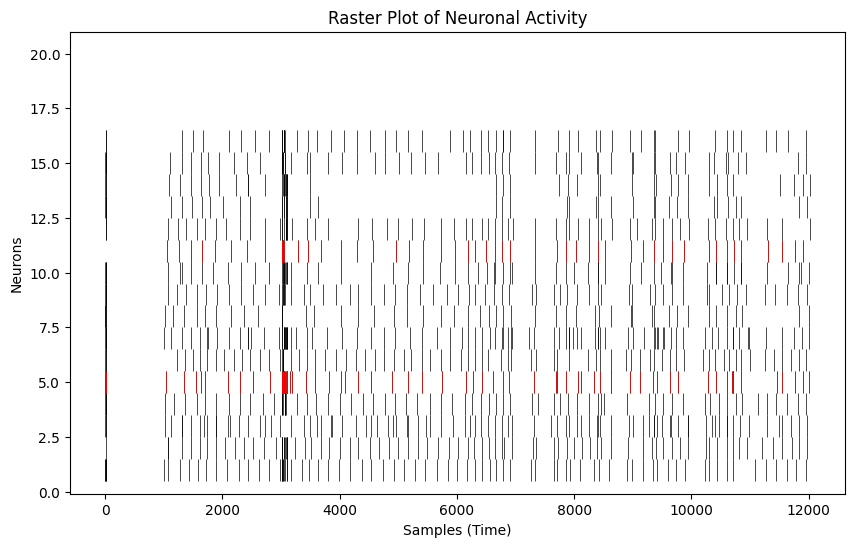

In [61]:
plt.figure(figsize=(10, 6))
for i in range(data_MU.shape[0]):
    spike_times = np.where(data_MU[i] == 1)[0]
    plt.vlines(spike_times, i + 0.5, i + 1.5, color='black',linewidth=0.5) 
    if i==4 or i==10:
        plt.vlines(spike_times, i + 0.5, i + 1.5, color='red',linewidth=0.5) 
    

plt.xlabel('Samples (Time)')
plt.ylabel('Neurons')
plt.title('Raster Plot of Neuronal Activity')
plt.ylim(-0.1, data_MU.shape[0] + 5)
plt.show()# data['fsamp']

Explained variance by component: [0.61467499 0.14661904 0.04646901 0.04087061 0.02990886]
Cumulative explained variance: [0.61467499 0.76129403 0.80776304 0.84863365 0.87854251]


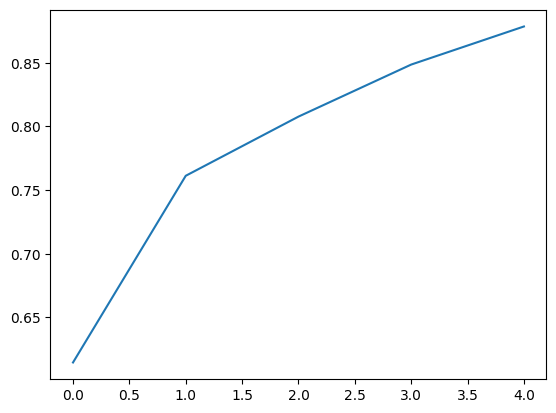

In [82]:
from sklearn.decomposition import PCA
import numpy as np

# Parameters
window_size_ms = 300  # Window size in milliseconds
sampling_rate = data['fsamp']  # Sampling rate in Hz (e.g., 20000 Hz)
window_size_samples = int((window_size_ms / 1000) * sampling_rate) 
# Convert window size to samples

# Initialize smoothed_mu_array with a floating-point data type to prevent overflow
smoothed_mu_array = np.zeros_like(data['MU'], dtype=np.float64)

# Smoothing the data['MU'] array with a moving average for each neuron
for i in range(data['MU'].shape[0]):
    smoothed_mu_array[i, :] = np.convolve(data['MU'][i, :], np.ones(window_size_samples) / window_size_samples, mode='same')

# Scale the smoothed data to represent firing rates in Hz (spikes per second)
firing_rate_mu = smoothed_mu_array * sampling_rate

# Performing PCA on the continuous firing rate data (e.g., selecting 5 principal components)
pca_mu = PCA(n_components=5)
principal_components_mu = pca_mu.fit_transform(firing_rate_mu.T)  # Transpose to get (samples, neurons) format
explained_variance_mu = pca_mu.explained_variance_ratio_
cumulative_explained_variance_mu = np.cumsum(explained_variance_mu)

# Print the explained variance for each component
print("Explained variance by component:", explained_variance_mu)
print("Cumulative explained variance:", cumulative_explained_variance_mu)

plt.plot(cumulative_explained_variance_mu)



0.7382126090685911
0.6286068463328501
0.5657069592159042
0.7605741646347238
0.6869535478336741
0.45647863590035287
0.5175336730219183
0.8028916317689668
0.6507266464860172
0.7035889294162666
0.7884703249309446
0.4874691457202519
0.7554254590230789
0.7683458556943027
0.5325371867629035
0.9449352896136124
0.7081218427726177
0.5671049026785143
0.7027629603794
0.8018515793098622
0.8573392682528787
0.7026085527931981
0.5847479694133491
0.7224958529991067
0.7350889225474713
0.828584349325917
0.7152839483117135
0.6770130498982517
0.704162702146881
0.6146749871613202


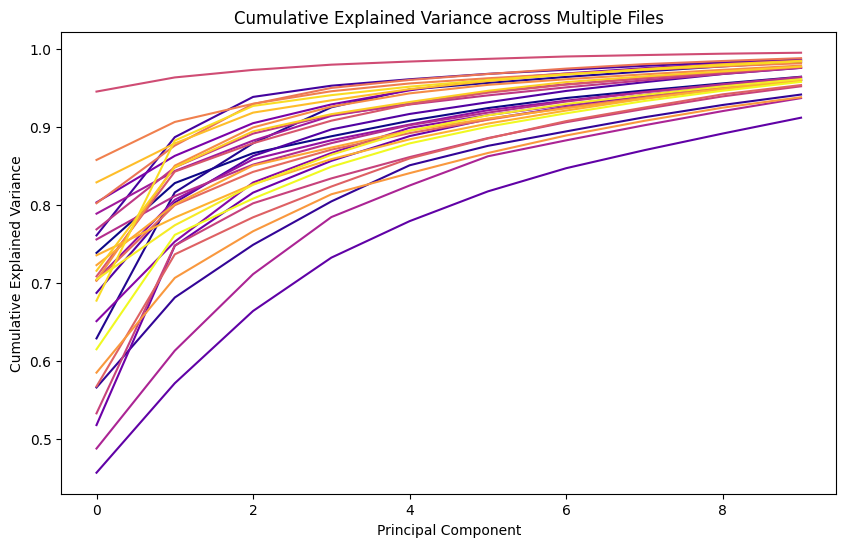

In [106]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
import pickle

# Parameters
window_size_ms = 300  # Window size in milliseconds
sampling_rate = data['fsamp']  # Replace with actual sampling rate, if known in advance

# Initialize a plot for cumulative explained variance across multiple files
plt.figure(figsize=(10, 6))
plt.xlabel("Principal Component")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance across Multiple Files")

# Create a color gradient (e.g., using the 'viridis' colormap)
cmap = plt.cm.plasma
colors = cmap(np.linspace(0, 1, 30))  # 30 gradient colors for each file

# Loop through each file, process the data, and compute cumulative explained variance
for i in range(30):
    # Define the dynamic file path
    pickle_file_path = f'Data_MN_Model/Data_Mario/E3_MB01_Day10High_{i+1}.pkl'
    
    # Load the pickle file
    with open(pickle_file_path, 'rb') as file:
        data = pickle.load(file)
    
    # Check if 'MU' data exists
    if 'MU' in data:
        # Convert window size to samples
        window_size_samples = int((window_size_ms / 1000) * sampling_rate)
        
        # Initialize smoothed_mu_array with a floating-point data type to prevent overflow
        smoothed_mu_array = np.zeros_like(data['MU'], dtype=np.float64)
        
        # Smoothing the data['MU'] array with a moving average for each neuron
        for neuron in range(data['MU'].shape[0]):
            smoothed_mu_array[neuron, :] = np.convolve(data['MU'][neuron, :], np.ones(window_size_samples) / window_size_samples, mode='same')
        
        # Scale the smoothed data to represent firing rates in Hz (spikes per second)
        firing_rate_mu = smoothed_mu_array * sampling_rate
        
        # Performing PCA on the continuous firing rate data (e.g., selecting 5 principal components)
        pca_mu = PCA(n_components=10)
        principal_components_mu = pca_mu.fit_transform(firing_rate_mu.T)  # Transpose to get (samples, neurons) format
        explained_variance_mu = pca_mu.explained_variance_ratio_
        cumulative_explained_variance_mu = np.cumsum(explained_variance_mu)
        print(cumulative_explained_variance_mu[0])
        # Plot cumulative explained variance for this file with a unique color
        plt.plot(cumulative_explained_variance_mu, color=colors[i], label=f'File {i+1}')
    else:
        print(f"'MU' data not found in file: {pickle_file_path}")

# Add a color bar to indicate progression across files
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=1, vmax=30))
# plt.colorbar(sm, label='File Number')

# Display the plot
plt.show()


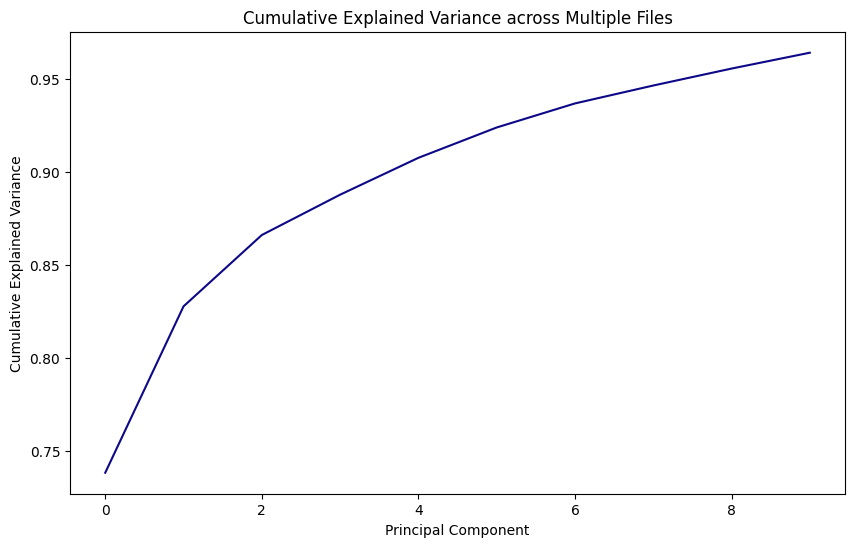

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_22976/1745811007.py:71: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(all_principal_components[:, 0], all_principal_components[:, 1], all_principal_components[:, 2], c=colors[i], alpha=0.6, s=10)


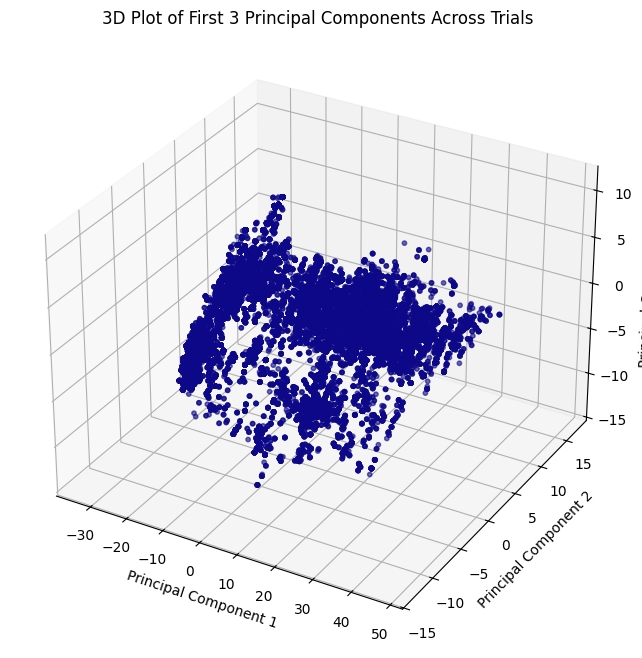

AttributeError: 'numpy.ndarray' object has no attribute 'append'

In [113]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # Import for 3D plotting
import pickle

# Parameters
window_size_ms = 300  # Window size in milliseconds

# Initialize a plot for cumulative explained variance across multiple files
plt.figure(figsize=(10, 6))
plt.xlabel("Principal Component")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance across Multiple Files")

# Create a color gradient (e.g., using the 'plasma' colormap)
cmap = plt.cm.plasma
colors = cmap(np.linspace(0, 1, 30))  # 30 gradient colors for each file

# Initialize a list to collect the first 3 PCs across trials for the 3D plot
all_principal_components = []

# Loop through each file, process the data, and compute cumulative explained variance
for i in range(2):
    # Define the dynamic file path
    pickle_file_path = f'Data_MN_Model/Data_Mario/E3_MB01_Day10High_{i+1}.pkl'
    
    # Load the pickle file
    with open(pickle_file_path, 'rb') as file:
        data = pickle.load(file)
    
    # Check if 'MU' data exists
    if 'MU' in data:
        # Get the sampling rate and convert window size to samples
        sampling_rate = data['fsamp']
        window_size_samples = int((window_size_ms / 1000) * sampling_rate)
        
        # Initialize smoothed_mu_array with a floating-point data type to prevent overflow
        smoothed_mu_array = np.zeros_like(data['MU'], dtype=np.float64)
        
        # Smoothing the data['MU'] array with a moving average for each neuron
        for neuron in range(data['MU'].shape[0]):
            smoothed_mu_array[neuron, :] = np.convolve(data['MU'][neuron, :], np.ones(window_size_samples) / window_size_samples, mode='same')
        
        # Scale the smoothed data to represent firing rates in Hz (spikes per second)
        firing_rate_mu = smoothed_mu_array * sampling_rate
        
        # Performing PCA on the continuous firing rate data
        pca_mu = PCA(n_components=10)
        principal_components_mu = pca_mu.fit_transform(firing_rate_mu.T)  # Transpose to get (samples, neurons) format
        explained_variance_mu = pca_mu.explained_variance_ratio_
        cumulative_explained_variance_mu = np.cumsum(explained_variance_mu)
        
        # Store the first 3 PCs for the 3D plot
        all_principal_components.append(principal_components_mu[:, :3])
        
        # Plot cumulative explained variance for this file with a unique color
        plt.plot(cumulative_explained_variance_mu, color=colors[i], label=f'File {i+1}')
    else:
        print(f"'MU' data not found in file: {pickle_file_path}")

# Display the cumulative explained variance plot
    plt.show()

    # Combine all first 3 PCs across trials for the 3D plot
    all_principal_components = np.vstack(all_principal_components)

    # 3D Plot of the first 3 principal components
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(all_principal_components[:, 0], all_principal_components[:, 1], all_principal_components[:, 2], c=colors[i], alpha=0.6, s=10)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.set_zlabel("Principal Component 3")
    ax.set_title("3D Plot of First 3 Principal Components Across Trials")

# Show the 3D plot
    plt.show()


In [44]:
window_size_ms = 300  # 300 ms window
sampling_rate = data['fsamp']  # 20 kHz
window_size_samples = int((window_size_ms / 1000) * sampling_rate)  # Convert window size to samples

# Smoothing the data['MU'] array with a moving average for each neuron
smoothed_mu_array = np.zeros_like(data['MU'])
for i in range(data['MU'].shape[0]):
    smoothed_mu_array[i, :] = np.convolve(data['MU'][i, :], np.ones(window_size_samples) / window_size_samples, mode='same')
    
smoothed_mu_array

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

In [52]:
# Check if there are any elements equal to 1 in smoothed_mu_array
contains_one = np.any(data['MU'][3,:] !=0)
contains_one = np.any(smoothed_mu_array!=0)

# Print the result
if contains_one:
    print("There is at least one '1' in smoothed_mu_array.")
else:
    print("There are no '1's in smoothed_mu_array.")


There are no '1's in smoothed_mu_array.


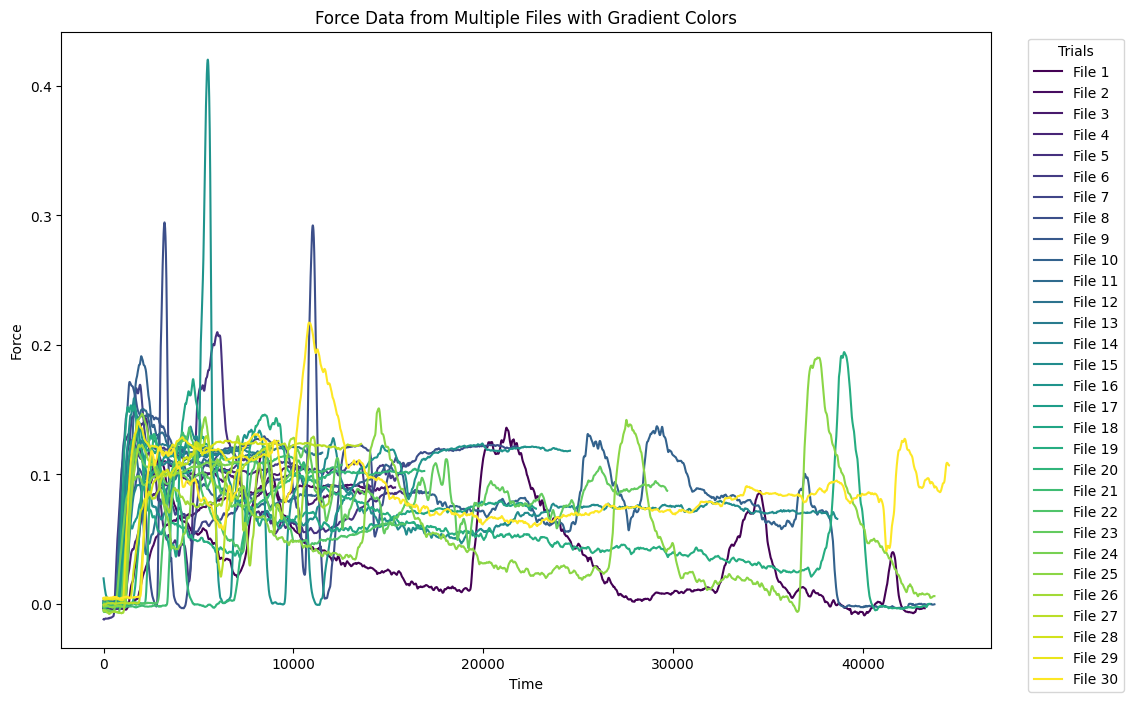

In [19]:
import pickle
import matplotlib.pyplot as plt
import numpy as np

# Initialize the plot with a larger figure size
plt.figure(figsize=(12, 8))
plt.xlabel('Time')
plt.ylabel('Force')
plt.title('Force Data from Multiple Files with Gradient Colors')

# Create a colormap (e.g., 'viridis' or 'plasma') and generate colors for each line
cmap = plt.cm.viridis
colors = cmap(np.linspace(0, 1, 30))  # 30 colors ranging from start to end of the colormap

# Loop through each file, load the data, and plot the 'Force' values on the same plot
for i in range(30):
    # Define the dynamic file path
    pickle_file_path = f'Data_MN_Model/Data_Mario/E3_MB01_Day10High_{i+1}.pkl'
    
    # Load the pickle file
    with open(pickle_file_path, 'rb') as file:
        data = pickle.load(file)
    
    # Plot the 'Force' data on the same figure with a unique color for each file
    plt.plot(data['Force'][0, :], color=colors[i], label=f'File {i+1}')

# Add a legend to identify files, setting it to display in a smaller, less obtrusive format
plt.legend(title="Trials", loc="upper right", bbox_to_anchor=(1.15, 1))
plt.show()
